
========== DATASET INFORMATION ==========

First 5 Records:
         Date      PM2.5        PM10        CO    AQI
0  2025-01-01  70.484907   67.928256  0.841776  117.5
1  2025-01-02  46.280286  101.627874  1.262746   95.9
2  2025-01-03  78.508122  114.068827  1.276999  141.8
3  2025-01-04  81.930165  124.655558  1.675716  153.2
4  2025-01-05  29.881367  127.780664  1.492289   81.2

Last 5 Records:
          Date      PM2.5        PM10        CO    AQI
55  2025-02-25  53.500199   96.762682  1.260406  104.8
56  2025-02-26  60.047439  115.816905  1.752682  122.9
57  2025-02-27  91.908944  110.546304  1.255997  159.0
58  2025-02-28  49.415040  150.044472  1.158477  107.6
59  2025-03-01  82.429010  104.016109  1.300039  145.6

Dataset Shape (Rows, Columns):
(60, 5)

Column Names:
['Date', 'PM2.5', 'PM10', 'CO', 'AQI']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  

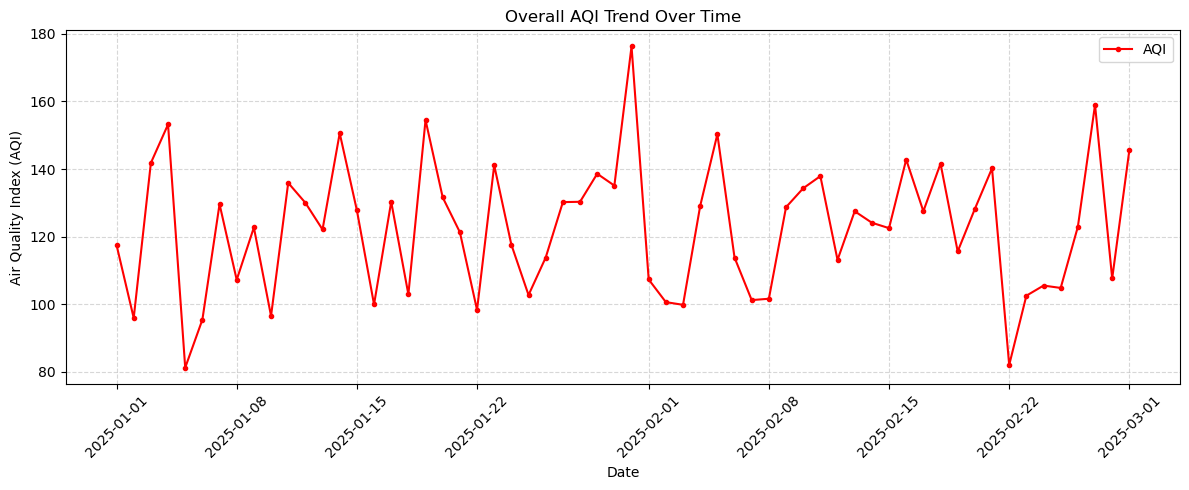

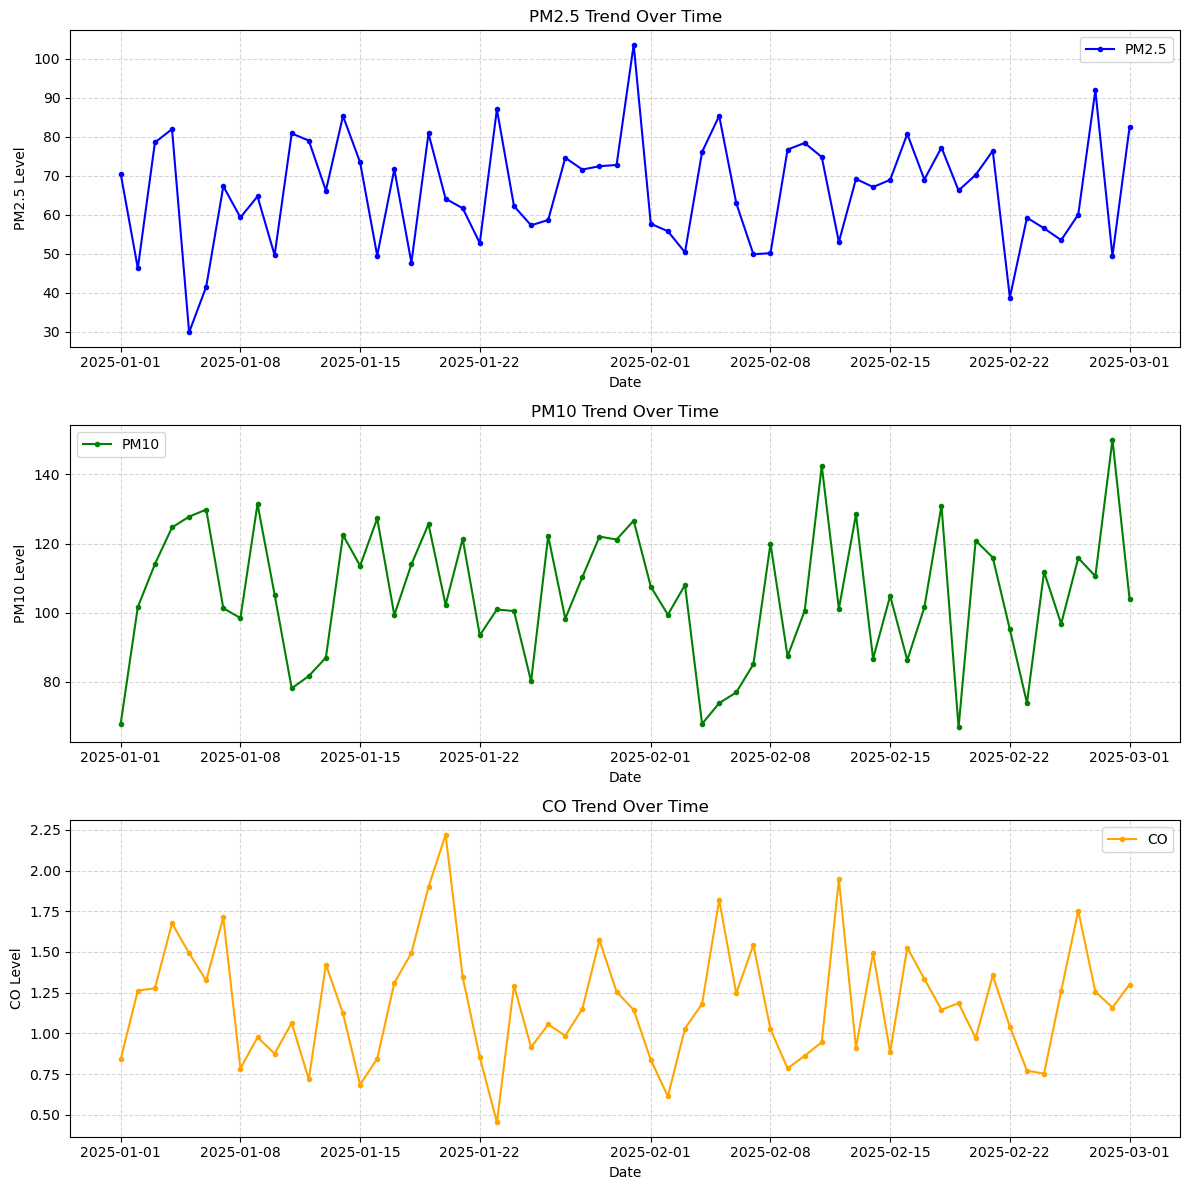

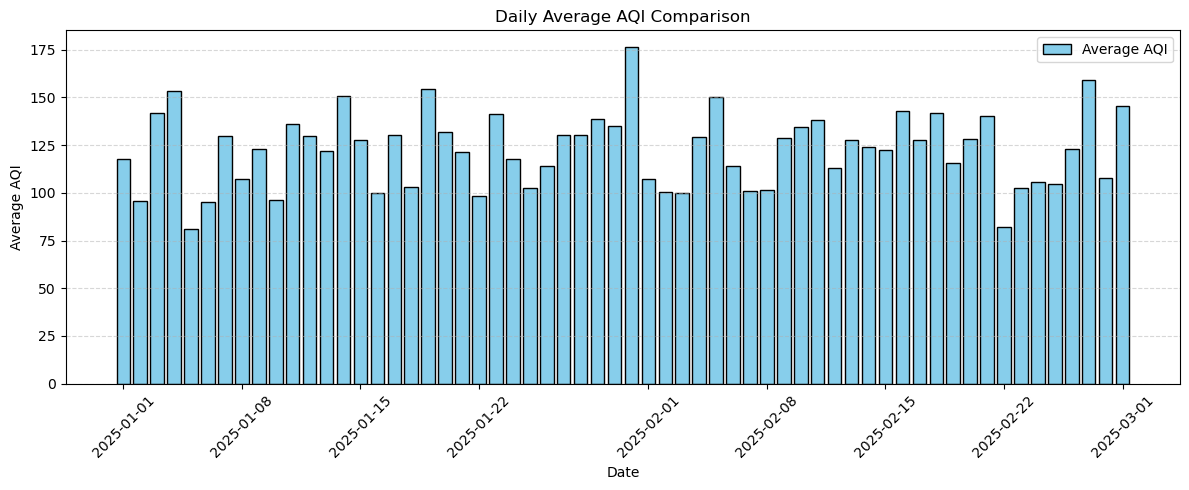

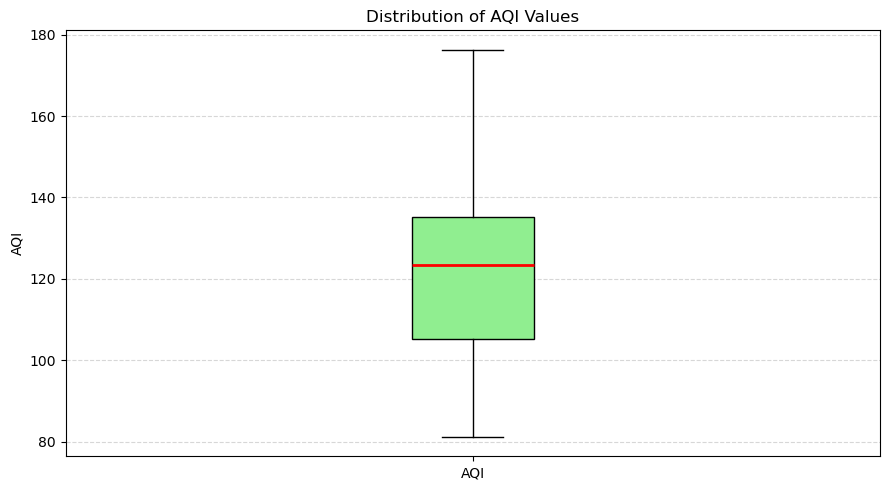

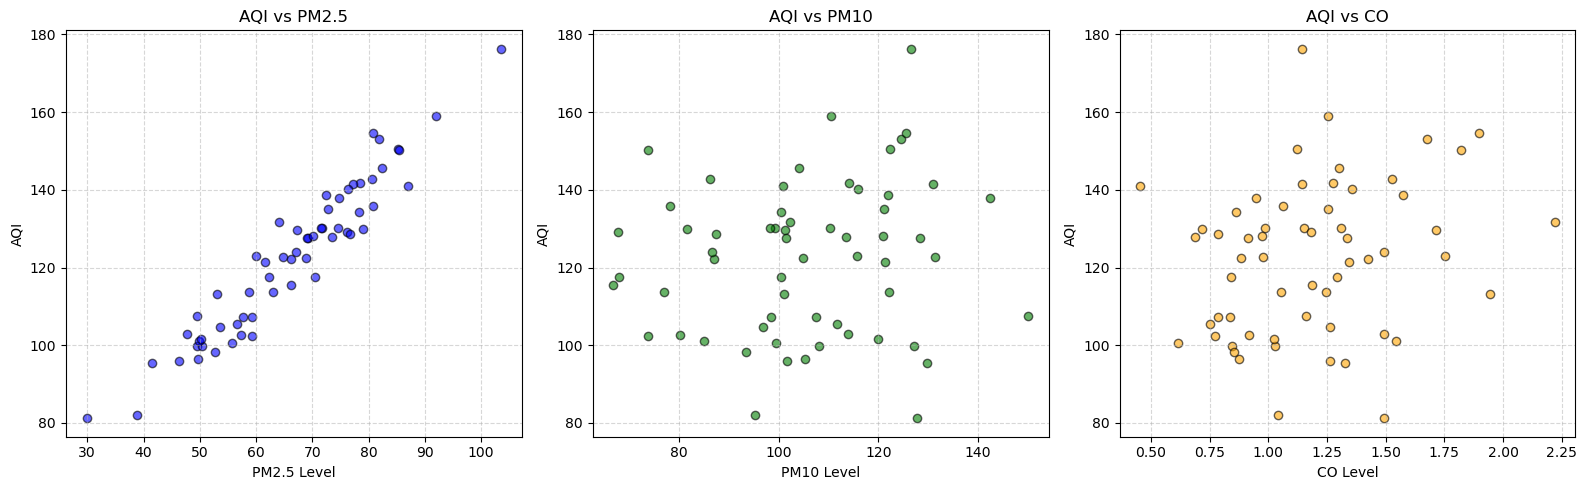

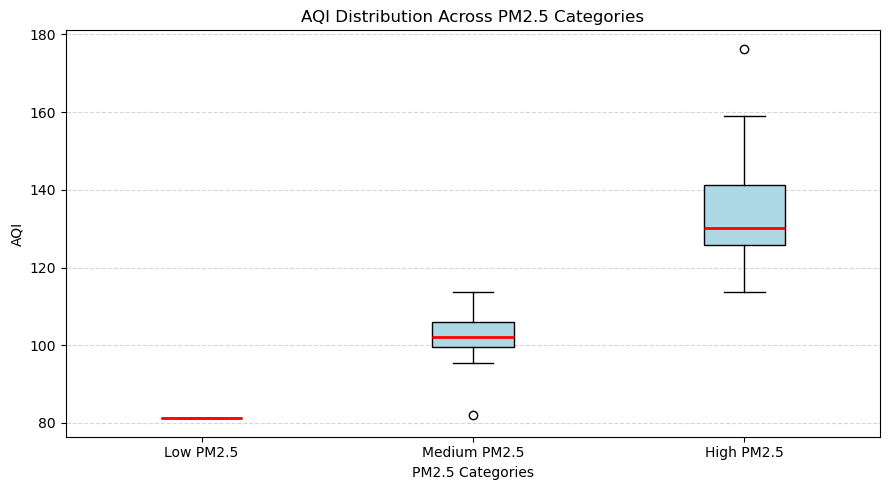

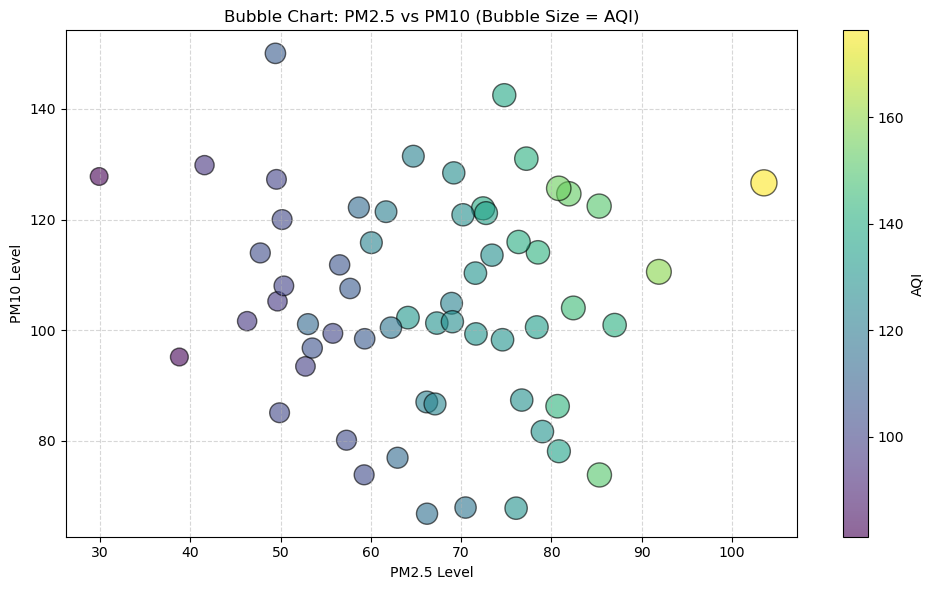


========== AQI ANALYSIS SUMMARY ==========
Average AQI: 122.49
Maximum AQI: 176.3
Minimum AQI: 81.2

Average Pollutant Levels:
PM2.5     66.175138
PM10     105.347769
CO         1.182678
dtype: float64

AQI Analysis Completed Successfully!


In [1]:

# Practical: Data Visualization using Matplotlib
# Problem: Analyzing Air Quality Index (AQI) Trends in a City

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Step 2: Load the dataset
df = pd.read_csv("City_Air_Quality.csv")

# Step 3: Explore the dataset
print("\n========== DATASET INFORMATION ==========")

# Display first five records
print("\nFirst 5 Records:")
print(df.head())

# Display last five records
print("\nLast 5 Records:")
print(df.tail())

# Display dataset shape
print("\nDataset Shape (Rows, Columns):")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types and non-null values
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
print(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


# Step 4: Data preprocessing

# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert pollutant and AQI columns into numeric format
numeric_cols = ["PM2.5", "PM10", "CO", "AQI"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing required values
df = df.dropna(subset=["Date", "PM2.5", "PM10", "CO", "AQI"])

# Sort records according to date
df = df.sort_values("Date")

# Display cleaned dataset
print("\nCleaned Dataset:")
print(df.head())


# Step 5: Overall AQI trend over time (Line Plot)

plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["AQI"],
    color="red",
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="AQI"
)

plt.title("Overall AQI Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Air Quality Index (AQI)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Step 6: Individual pollutant trends (Separate Line Plots)

pollutants = ["PM2.5", "PM10", "CO"]

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

colors = ["blue", "green", "orange"]

for i, pollutant in enumerate(pollutants):

    axes[i].plot(
        df["Date"],
        df[pollutant],
        color=colors[i],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=pollutant
    )

    axes[i].set_title(pollutant + " Trend Over Time")
    axes[i].set_xlabel("Date")
    axes[i].set_ylabel(pollutant + " Level")
    axes[i].legend()
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# Step 7: Compare AQI values across different dates (Bar Plot)

# Group AQI values by date
daily_aqi = df.groupby("Date")["AQI"].mean()

plt.figure(figsize=(12, 5))

plt.bar(
    daily_aqi.index,
    daily_aqi.values,
    color="skyblue",
    edgecolor="black",
    label="Average AQI"
)

plt.title("Daily Average AQI Comparison")
plt.xlabel("Date")
plt.ylabel("Average AQI")
plt.legend()
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# Step 8: AQI distribution using Box Plot

plt.figure(figsize=(9, 5))

plt.boxplot(
    df["AQI"],
    patch_artist=True,
    boxprops=dict(facecolor="lightgreen"),
    medianprops=dict(color="red", linewidth=2)
)

plt.title("Distribution of AQI Values")
plt.ylabel("AQI")
plt.xticks([1], ["AQI"])
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# Step 9: Relationship between AQI and pollutant levels (Scatter Plots)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colors = ["blue", "green", "orange"]

for i, pollutant in enumerate(pollutants):

    axes[i].scatter(
        df[pollutant],
        df["AQI"],
        color=colors[i],
        alpha=0.6,
        edgecolor="black"
    )

    axes[i].set_title("AQI vs " + pollutant)
    axes[i].set_xlabel(pollutant + " Level")
    axes[i].set_ylabel("AQI")
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


# Step 10: AQI distribution for different pollutant categories

# Divide PM2.5 levels into categories
df["Pollutant_Category"] = pd.cut(
    df["PM2.5"],
    bins=[-np.inf, 30, 60, np.inf],
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(9, 5))

category_data = [
    df[df["Pollutant_Category"] == category]["AQI"].dropna()
    for category in ["Low", "Medium", "High"]
]

plt.boxplot(
    category_data,
    tick_labels=["Low PM2.5", "Medium PM2.5", "High PM2.5"],
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    medianprops=dict(color="red", linewidth=2)
)

plt.title("AQI Distribution Across PM2.5 Categories")
plt.xlabel("PM2.5 Categories")
plt.ylabel("AQI")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# Step 11: Bubble Chart (AQI vs PM2.5 and PM10)

plt.figure(figsize=(10, 6))

plt.scatter(
    df["PM2.5"],
    df["PM10"],
    s=df["AQI"].clip(lower=0) * 2,
    c=df["AQI"],
    cmap="viridis",
    alpha=0.6,
    edgecolor="black"
)

plt.colorbar(label="AQI")
plt.title("Bubble Chart: PM2.5 vs PM10 (Bubble Size = AQI)")
plt.xlabel("PM2.5 Level")
plt.ylabel("PM10 Level")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# Step 12: Final summary

print("\n========== AQI ANALYSIS SUMMARY ==========")

print("Average AQI:", round(df["AQI"].mean(), 2))
print("Maximum AQI:", df["AQI"].max())
print("Minimum AQI:", df["AQI"].min())

print("\nAverage Pollutant Levels:")
print(df[["PM2.5", "PM10", "CO"]].mean())

print("\nAQI Analysis Completed Successfully!")


In [4]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("City_Air_Quality.csv")

In [7]:
df.head()

,Date,PM2.5,PM10,CO,AQI
0,2025-01-01,70.484907,67.928256,0.841776,117.5
1,2025-01-02,46.280286,101.627874,1.262746,95.9
2,2025-01-03,78.508122,114.068827,1.276999,141.8
3,2025-01-04,81.930165,124.655558,1.675716,153.2
4,2025-01-05,29.881367,127.780664,1.492289,81.2


In [8]:
df.isnull().sum()

Date     0
PM2.5    0
PM10     0
CO       0
AQI      0
dtype: int64

In [9]:
df.describe()

,PM2.5,PM10,CO,AQI
count,60.000000,60.000000,60.000000,60.000000
mean,66.175138,105.347769,1.182678,122.491667
std,14.141657,19.254347,0.356892,19.695515
min,29.881367,66.816989,0.453784,81.200000
25%,56.344877,94.722651,0.905380,105.325000
50%,67.200736,104.440085,1.154600,123.500000
75%,76.450059,121.227305,1.347814,135.300000
max,103.549657,150.044472,2.219852,176.300000


In [12]:
print(df.columns.tolist())

['Date', 'PM2.5', 'PM10', 'CO', 'AQI']


In [13]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

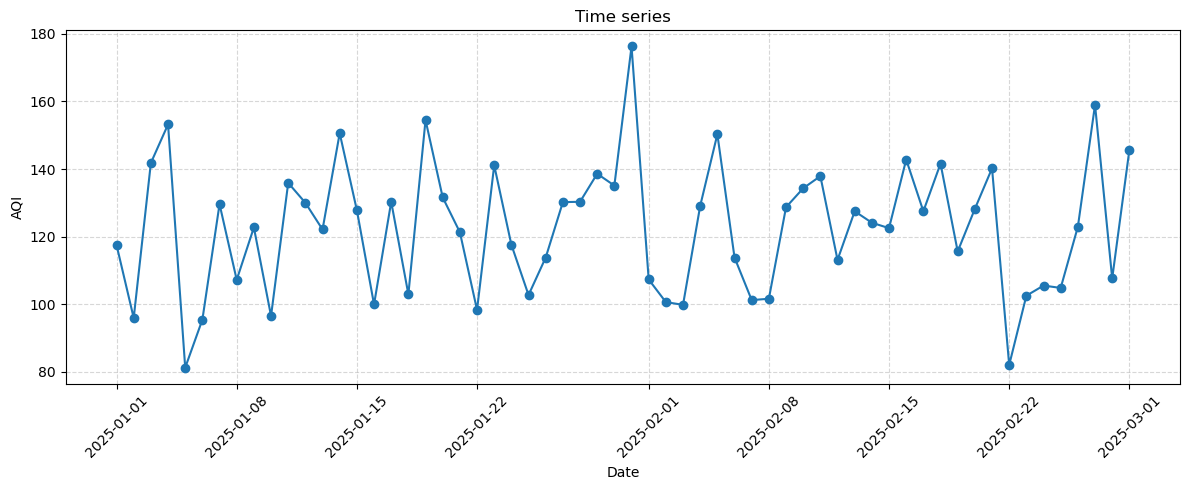

In [31]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["Date"],
    df["AQI"],
    marker="o",
    label="AQI"
)
plt.title("Time series")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.grid(True, linestyle="--", alpha=0.5)



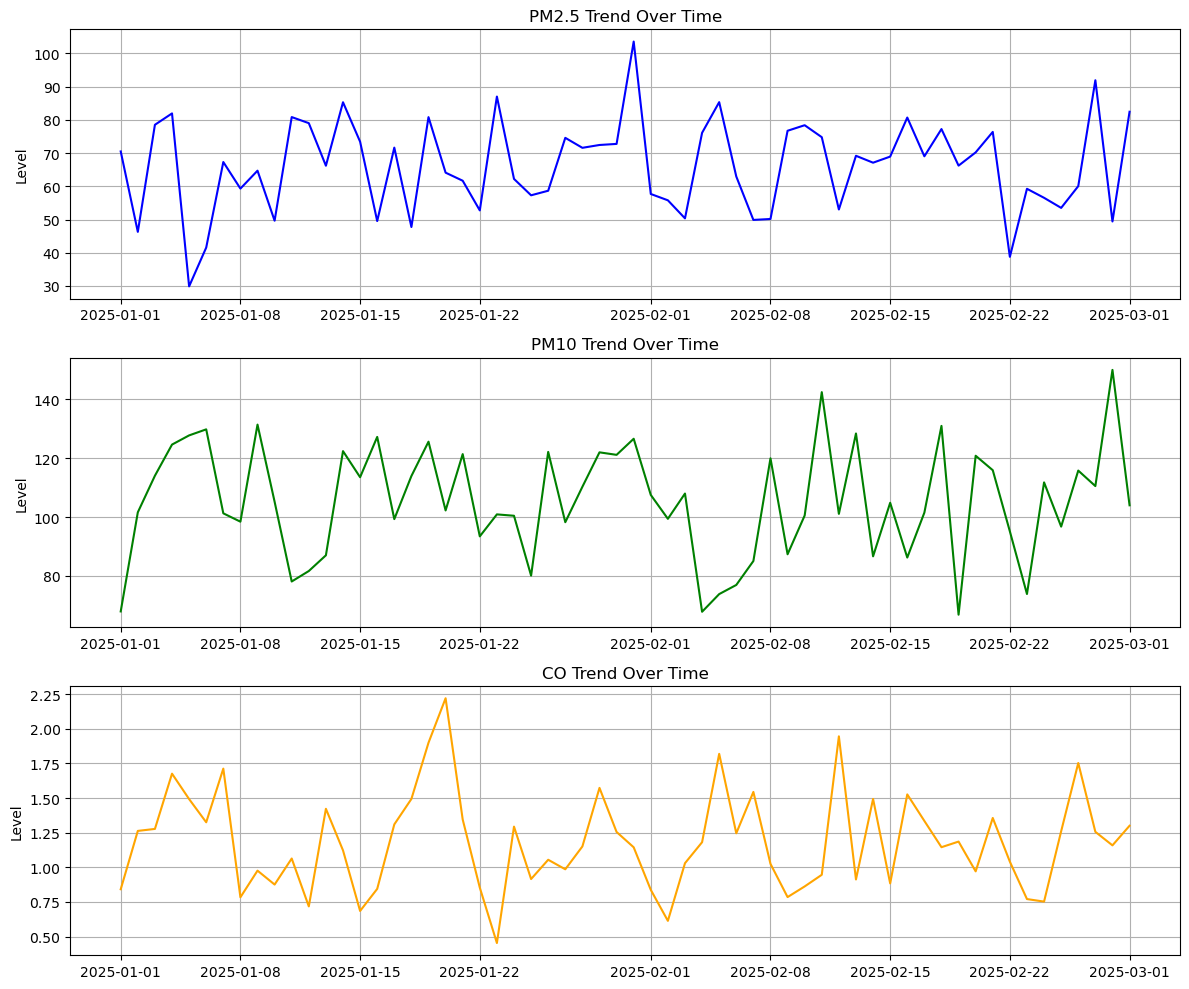

In [36]:
pollutants = ["PM2.5", "PM10", "CO"]
colors = ["blue", "green", "orange"]

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for i in range(3):
    axes[i].plot(df["Date"], df[pollutants[i]], color=colors[i])
    axes[i].set_title(pollutants[i] + " Trend Over Time")
    axes[i].set_ylabel("Level")
    axes[i].grid()

plt.tight_layout()
plt.show()

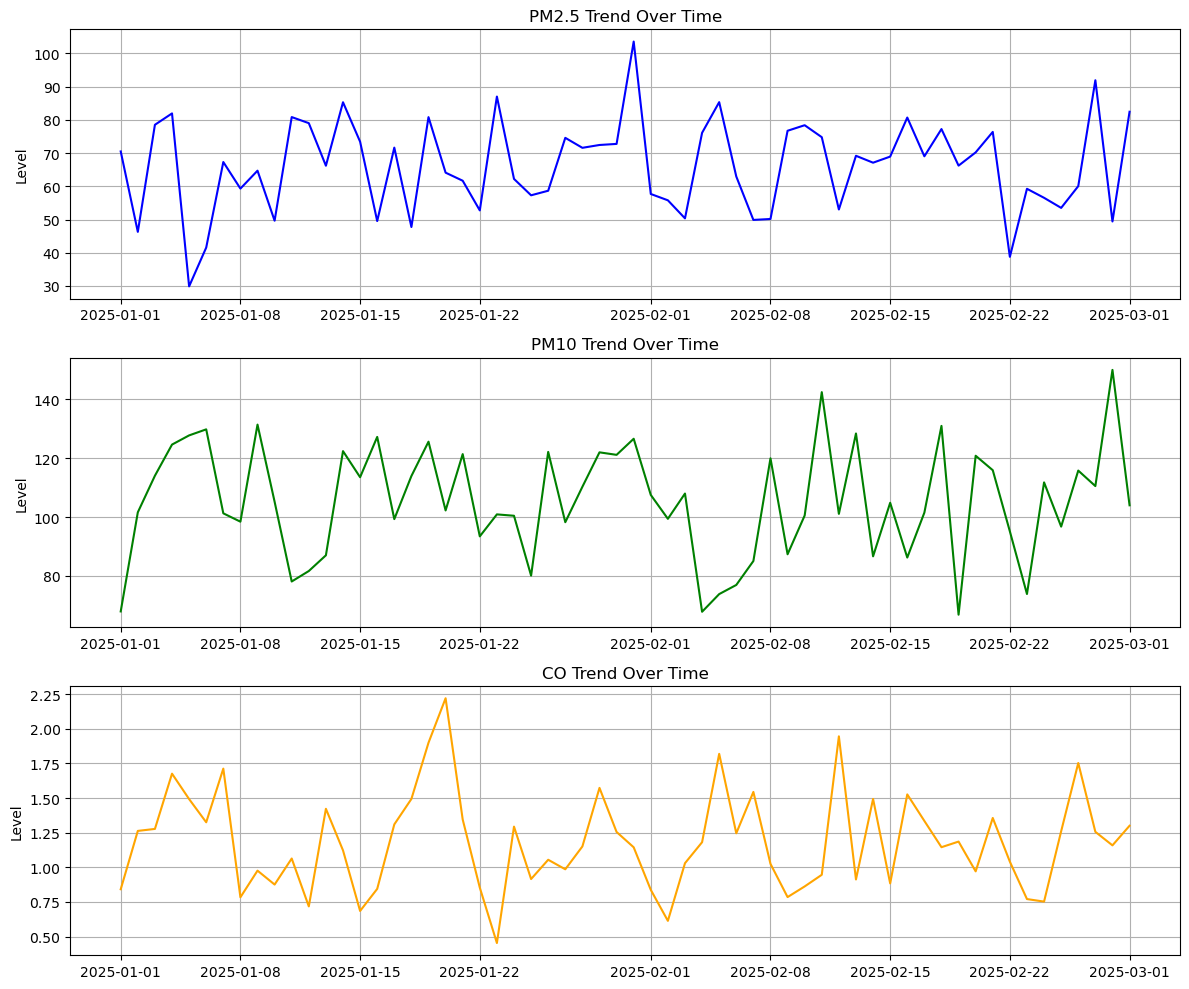

In [43]:
pollutants = ["PM2.5", "PM10", "CO"]
colors = ["blue", "green", "orange"]

fig, axes = plt.subplots(3,1, figsize=(12,10))

for i in range(3):
    axes[i].plot(df["Date"], df[pollutants[i]], color=colors[i])
    axes[i].set_title(pollutants[i] + " Trend Over Time")
    axes[i].set_ylabel("Level")
    axes[i].grid()

plt.tight_layout()
plt.show()

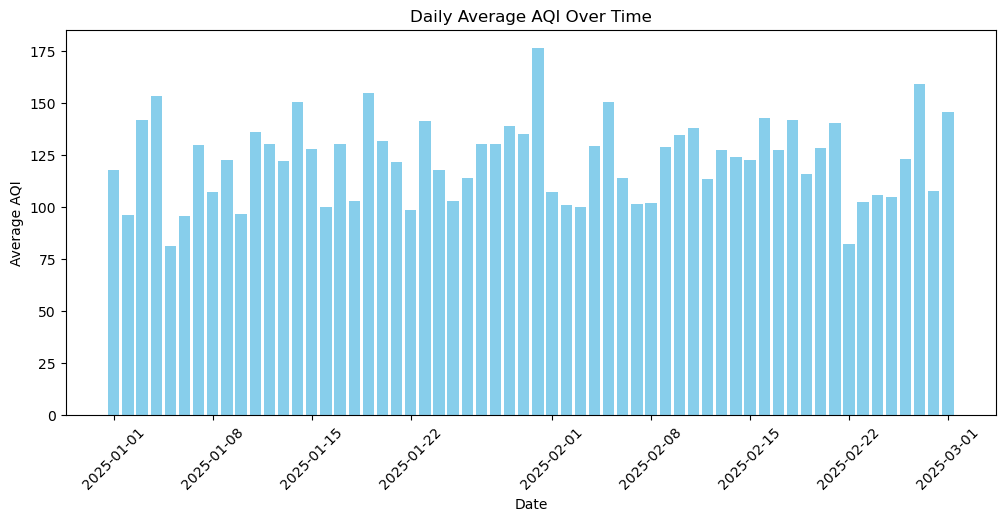

In [46]:
daily_aqi = df.groupby("Date")["AQI"].mean()

plt.figure(figsize=(12, 5))

plt.bar(daily_aqi.index, daily_aqi.values, color="skyblue")

plt.title("Daily Average AQI Over Time")
plt.xlabel("Date")
plt.ylabel("Average AQI")

plt.xticks(rotation=45)
plt.show()

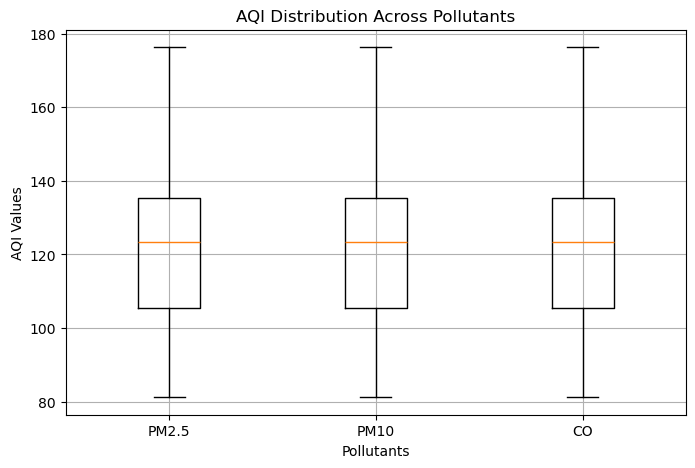

In [51]:
plt.figure(figsize=(8, 5))

plt.boxplot([
    df[df["PM2.5"].notna()]["AQI"].dropna(),
    df[df["PM10"].notna()]["AQI"].dropna(),
    df[df["CO"].notna()]["AQI"].dropna()
])

plt.xticks([1, 2, 3], ["PM2.5", "PM10", "CO"])

plt.title("AQI Distribution Across Pollutants")
plt.xlabel("Pollutants")
plt.ylabel("AQI Values")
plt.grid()
plt.show()
plt.show()

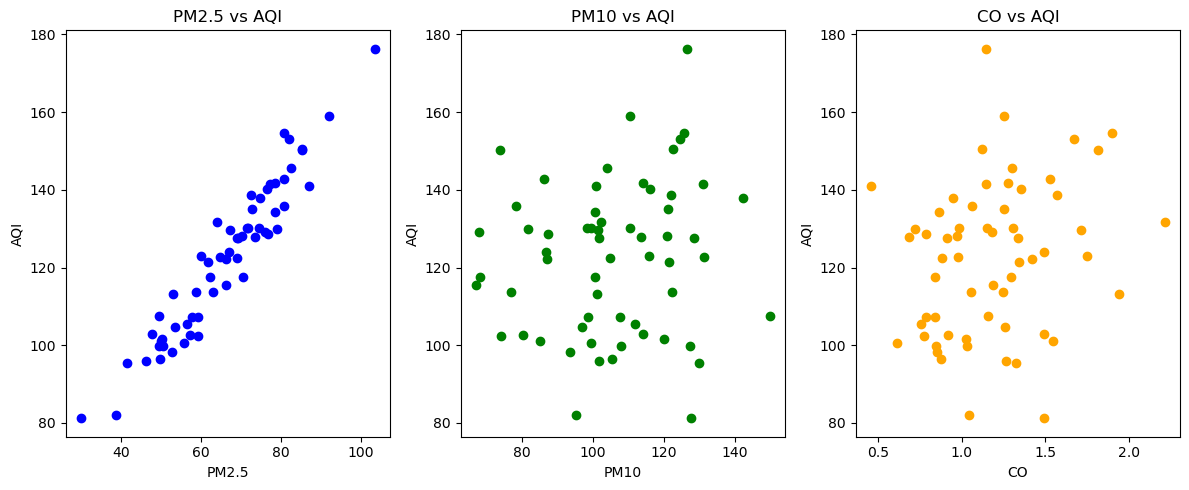

In [53]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.scatter(df["PM2.5"], df["AQI"], color="blue")
plt.xlabel("PM2.5")
plt.ylabel("AQI")
plt.title("PM2.5 vs AQI")

plt.subplot(1, 3, 2)
plt.scatter(df["PM10"], df["AQI"], color="green")
plt.xlabel("PM10")
plt.ylabel("AQI")
plt.title("PM10 vs AQI")

plt.subplot(1, 3, 3)
plt.scatter(df["CO"], df["AQI"], color="orange")
plt.xlabel("CO")
plt.ylabel("AQI")
plt.title("CO vs AQI")

plt.tight_layout()
plt.show()